# Task 3

## Setup: Imports, Dependencies and Paths

In [1]:
!pip install ultralytics

# TODO: Add all dependencies

In [ ]:
import json
import os
import random
import shutil
from pathlib import Path
import numpy as np
import yaml
from ultralytics import YOLO
import matplotlib.pyplot as plt
import torch

%matplotlib inline

# TODO: Put all imports here

In [3]:
# fixed seed for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Paths
HERE = Path.cwd()  # task3/
REPO = HERE.parent # Project root
DATASET_DIR = (HERE / "../8-BallPool.v2i.yolov8").resolve() # TODO: Change this to the actual dataset directory
DATA_YAML = DATASET_DIR / "data.yaml"
MODEL_PT = HERE / "model.pt" # where we keep the best weights
RUNS_DIR = HERE / "runs" 

# Directory for input and output JSON files
INPUT_JSON = HERE / "../example_json/input.json" # TODO: Change this to the actual input JSON file path
OUTPUT_JSON = HERE / "detection_results.json" # TODO: Change this to the desired output JSON file path

# Check directories
print("Working directory:", HERE)
print("Dataset directory:", DATASET_DIR)

# device: '0' for first GPU, 'cpu' otherwise
device = "0" if torch.cuda.is_available() else "cpu"
print("using device:", device)

Working directory: /home/vanessa/Dados/Uni/4ano/2semestre/VC/ComputerVision/task3
Dataset directory: /home/vanessa/Dados/Uni/4ano/2semestre/VC/ComputerVision/8-BallPool.v2i.yolov8
using device: 0


## Part 1 - Ball Detection on 8-Ball Pool Table Images

### 1.1 Data Preparation

The dataset is already in YOLOv8 format, with `images/` and `labels/` folders and a train/valid/test split. The only adaptation needed is on the labels: the export ships five classes alphabetically (`Black`, `Cue`, `Dot`, `Solid`, `Striped`), so we drop the `Dot` annotations and remap the remaining class ids into the fixed `CLASS_NAMES` order, then write a four-class `data.yaml`.

In [4]:
# Define class names and mapping
CLASS_NAMES = ["cue", "solid", "striped", "black"]
NAME_TO_CLASS = {"cue": 0, "solid": 1, "striped": 2, "black": 3}

# Check if data.yaml already lists the four classes
names = [str(n) for n in yaml.safe_load(DATA_YAML.read_text())["names"]]
if names == CLASS_NAMES:
    print("data.yaml already lists the four classes; nothing to do")
else:
    # map each source class id -> our class id (ids not in the map are dropped)
    remap = {i: NAME_TO_CLASS[n.lower()] for i, n in enumerate(names) if n.lower() in NAME_TO_CLASS}

    # rewrite every label file: drop dropped-class lines and remap the kept ones
    for split in ("train", "valid", "test"):
        for label_file in (DATASET_DIR / split / "labels").glob("*.txt"):
            lines = []
            for line in label_file.read_text().splitlines():
                parts = line.split()
                if parts and int(parts[0]) in remap:
                    lines.append(" ".join([str(remap[int(parts[0])]), *parts[1:]]))
            label_file.write_text("\n".join(lines))

    # write a 4-class data.yaml
    DATA_YAML.write_text(
        f"path: {DATASET_DIR.resolve()}\n"
        "train: train/images\nval: valid/images\ntest: test/images\n"
        f"nc: {len(CLASS_NAMES)}\nnames: {CLASS_NAMES}\n"
    )
    print("dataset remapped to 4 classes")

data.yaml already lists the four classes; nothing to do


### 1.2 Fine-Tune YOLOv8

We start from a pretrained YOLOv8 checkpoint and fine-tune on the prepared dataset.

In [ ]:
# hyperparameters
model_name = "yolov8n.pt"
epochs = 100 
imgsz = 832 # TODO: Is this a good image size?
batch = 4

In [6]:
# load a pretrained model and fine-tune it
model = YOLO(model_name)
model.train(
    data=str(DATA_YAML),
    epochs=epochs,
    imgsz=imgsz,
    batch=batch,
    device=device,
    seed=42,
    project=str(RUNS_DIR),
    name="ball_detection",
    exist_ok=True,
)

# keep a copy of the best weights
best = Path(model.trainer.best)
shutil.copy2(best, MODEL_PT)
print("best weights:", best)

New https://pypi.org/project/ultralytics/8.4.61 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.60 🚀 Python-3.12.13 torch-2.12.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 3770MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/vanessa/Dados/Uni/4ano/2semestre/VC/ComputerVision/8-BallPool.v2i.yolov8/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=832, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, m

### 1.3 Evaluate

In [7]:
model = YOLO(str(MODEL_PT))
metrics = model.val(data=str(DATA_YAML), imgsz=imgsz, device=device, split="test")

print(f"mAP@0.5:      {metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95: {metrics.box.map:.4f}")
for i, name in enumerate(CLASS_NAMES):
    print(f"AP@0.5 [{name}]: {metrics.box.ap50[i]:.4f}")

Ultralytics 8.4.60 🚀 Python-3.12.13 torch-2.12.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 3770MiB)
Model summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 298.3±95.8 MB/s, size: 157.7 KB)
val: Scanning /home/vanessa/Dados/Uni/4ano/2semestre/VC/ComputerVision/8-BallPool.v2i.yolov8/test/labels.cache... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 6.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.3it/s 1.6s2.3s
                   all         20        226      0.978      0.907      0.953      0.814
                   cue         20         20      0.985          1      0.995      0.869
                 solid         18         92      0.976      0.897      0.978      0.806
               striped         18         95      0.975      0.836      0.923      0.783
                 black         19         19      0.976

### 1.4 Predict

Run detection over the images listed in an input JSON and write detections. Box coordinates are normalised to the `[0, 1]` range.

In [ ]:
conf = 0.5 # confidence threshold for predictions

# read the image list from the input JSON and resolve the paths
spec = json.loads(INPUT_JSON.read_text())
image_paths = [str(REPO / p) for p in spec["image_path"]]

# predict on all images at once
results = model.predict(image_paths, conf=conf, device=device, verbose=False)

# build the output JSON and save the annotated images
out_dir = HERE / "predictions"
out_dir.mkdir(exist_ok=True)

records = []
for entry, result in zip(spec["image_path"], results): # TODO: What does the correct ouput JSON format look like?
    h, w = result.orig_shape
    balls = []
    for box in result.boxes:
        cls_id = int(box.cls.item())
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        balls.append({
            "class": CLASS_NAMES[cls_id],
            "confidence": round(float(box.conf.item()), 4),
            "xmin": round(x1 / w, 6),
            "ymin": round(y1 / h, 6),
            "xmax": round(x2 / w, 6),
            "ymax": round(y2 / h, 6),
        })
    records.append({"image_path": os.path.basename(entry), "num_balls": len(balls), "balls": balls})
    result.save(filename=str(out_dir / os.path.basename(entry)))
    print(f"{os.path.basename(entry)}: {len(balls)} balls")

assert len(records) == len(image_paths)
OUTPUT_JSON.write_text(json.dumps({"results": records}, indent=2))
print("wrote", OUTPUT_JSON)

106_png.rf.28ee53acf89d9e7f17b2fb26185597a0.jpg: 10 balls
10a_png.rf.bdc9984ba169594ea32b012098ad10dd.jpg: 12 balls
110_png.rf.9a38b6057e543f83b58aa59b9748688b.jpg: 2 balls
114_png.rf.98b2144c25b9f48816abd7edb00f365c.jpg: 16 balls
115_png.rf.ed51d53dd5c384b1f26a2b6ece52ad69.jpg: 11 balls
117_png.rf.8cc2251ee5c44b6bd3734b39795c7cc9.jpg: 9 balls
119_png.rf.eff91a09289a82f634d7b231b06dbbdd.jpg: 9 balls
11f_png.rf.eb0169eccfb6b264a582491457ff37b6.jpg: 3 balls
121_png.rf.782a44b8496f239b5f996a6ed498e63a.jpg: 11 balls
122_png.rf.7df85841dad9a1f2d79c7f510f562052.jpg: 16 balls
123_png.rf.c77820fd3abbca5d6265af63564f9564.jpg: 12 balls
127_png.rf.9f6501b0ba0e856cf6dd9e59f65ce574.jpg: 16 balls
128_png.rf.536c0efc16ea6cf15f4f2a6f280450cf.jpg: 10 balls
129_png.rf.eb2bbec526ed5285770c494673de2c04.jpg: 9 balls
12t_png.rf.80855510c9a4d8a3a88e103ed8baeeb7.jpg: 8 balls
130_png.rf.21f92398160a76a64b948884e4c8103c.jpg: 12 balls
132_png.rf.071b2e2111df71728a6b770afd959117.jpg: 11 balls
133_png.rf.a4164ecd7

Show some predictions:

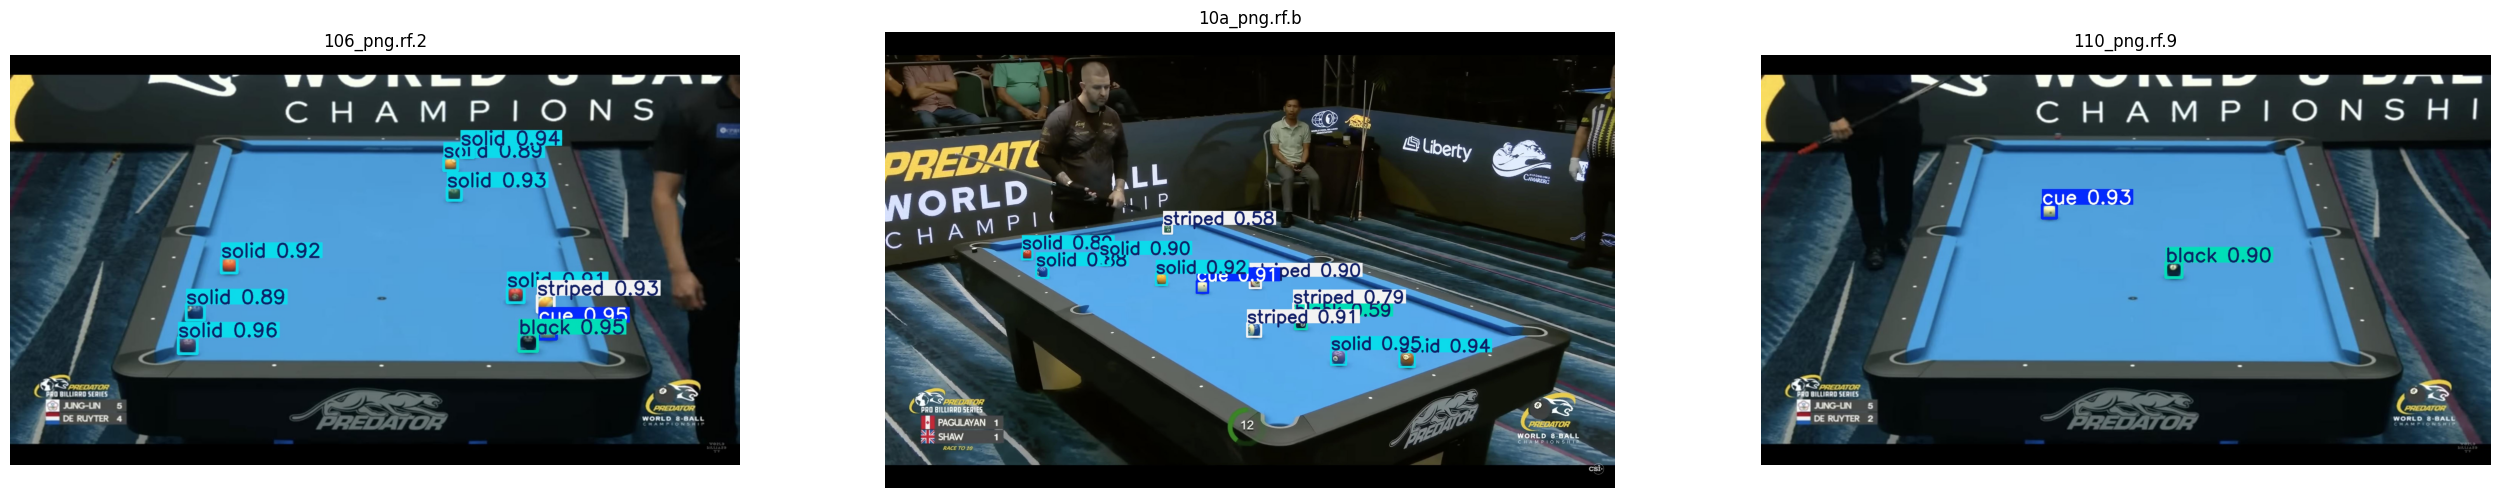

In [14]:
# Show the first N_SHOW predictions
N_SHOW = 3 
saved = sorted(out_dir.glob("*.jpg"))[:N_SHOW]
f, axarr = plt.subplots(1, N_SHOW, figsize=(32, 10)) 
for i, path in enumerate(saved):
    img = plt.imread(path)
    axarr[i].imshow(img, cmap="gray", vmin=0, vmax=255)
    axarr[i].set_title(path.name[:12])
    axarr[i].axis("off") 

## Part 2 - Table Retrieval

In [ ]:
#TODO